In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_path = "/content/drive/MyDrive/PM25_project"
output_path = os.path.join(project_path, "outputs")
figure_path = os.path.join(project_path, "figures")

print("Project folder exists:", os.path.exists(project_path))
print("Output folder exists:", os.path.exists(output_path))
print("Figures folder exists:", os.path.exists(figure_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder exists: True
Output folder exists: True
Figures folder exists: True


In [4]:
regression_results_path = os.path.join(
    output_path, "final_regression_test_predictions.csv"
)

regression_results = pd.read_csv(regression_results_path)

print("Dataset shape:", regression_results.shape)
print("\nColumns:")
print(regression_results.columns.tolist())

print("\nFirst 5 rows:")
display(regression_results.head())

print("\nMissing values:")
print(regression_results.isnull().sum())

Dataset shape: (1098, 7)

Columns:
['City', 'Target_Date', 'PM2.5_next_day', 'PM2.5', 'PM2.5_roll_mean_7', 'SVR_prediction', 'Period']

First 5 rows:


,City,Target_Date,PM2.5_next_day,PM2.5,PM2.5_roll_mean_7,SVR_prediction,Period
0,Bengaluru,2020-01-01,30.71,42.54,41.027143,40.812192,Pre-lockdown
1,Bengaluru,2020-01-02,25.78,30.71,40.345714,32.348639,Pre-lockdown
2,Bengaluru,2020-01-03,29.66,25.78,37.704286,28.639694,Pre-lockdown
3,Bengaluru,2020-01-04,52.62,29.66,35.752857,30.560100,Pre-lockdown
4,Bengaluru,2020-01-05,52.64,52.62,38.235714,46.427885,Pre-lockdown



Missing values:
City                 0
Target_Date          0
PM2.5_next_day       0
PM2.5                0
PM2.5_roll_mean_7    0
SVR_prediction       0
Period               0
dtype: int64


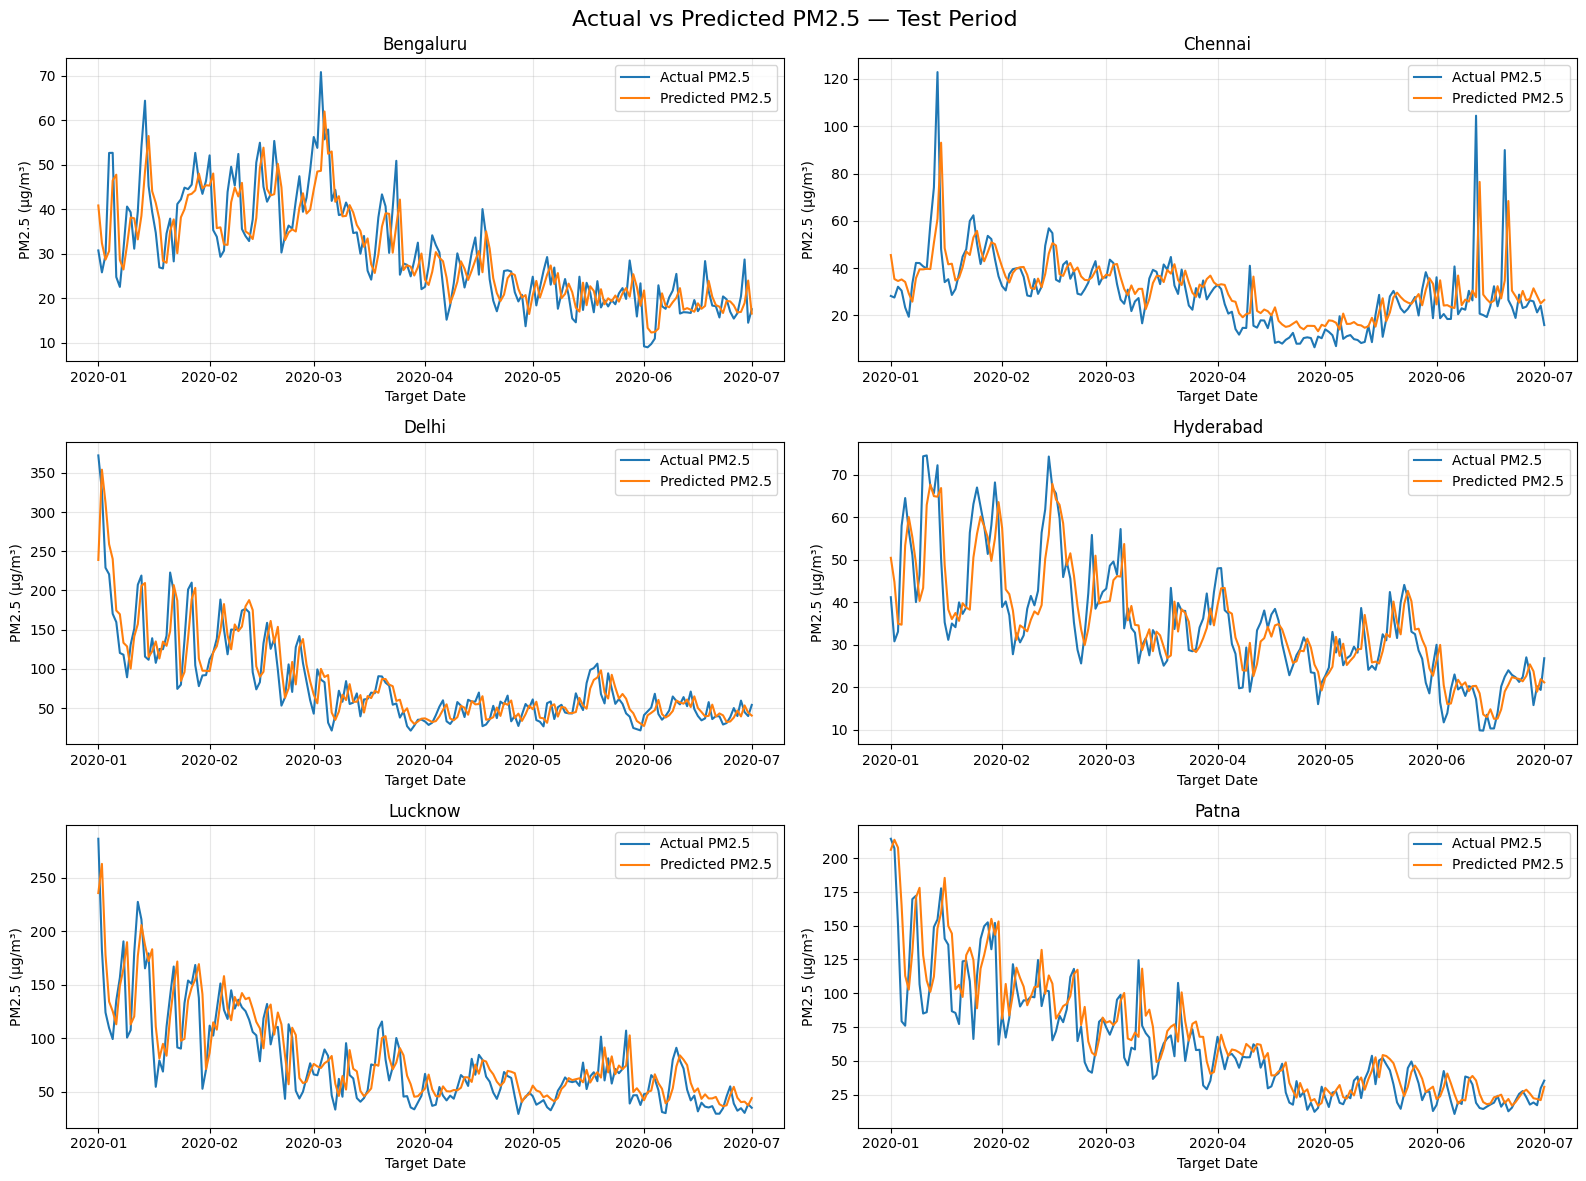

In [5]:
# Convert target dates into datetime format
regression_results["Target_Date"] = pd.to_datetime(
    regression_results["Target_Date"]
)

# Get the list of cities
cities = sorted(regression_results["City"].unique())

# Create a 3 x 2 subplot layout
fig, axes = plt.subplots(3, 2, figsize=(16, 12))

axes = axes.flatten()

for i, city in enumerate(cities):

    city_data = regression_results[
        regression_results["City"] == city
    ].sort_values("Target_Date")

    axes[i].plot(
        city_data["Target_Date"],
        city_data["PM2.5_next_day"],
        label="Actual PM2.5",
        linewidth=1.5
    )

    axes[i].plot(
        city_data["Target_Date"],
        city_data["SVR_prediction"],
        label="Predicted PM2.5",
        linewidth=1.5
    )

    axes[i].set_title(city)
    axes[i].set_xlabel("Target Date")
    axes[i].set_ylabel("PM2.5 (µg/m³)")
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle(
    "Actual vs Predicted PM2.5 — Test Period",
    fontsize=16
)

plt.tight_layout()

# Save the figure
plt.savefig(
    os.path.join(figure_path, "actual_vs_predicted_timeseries.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

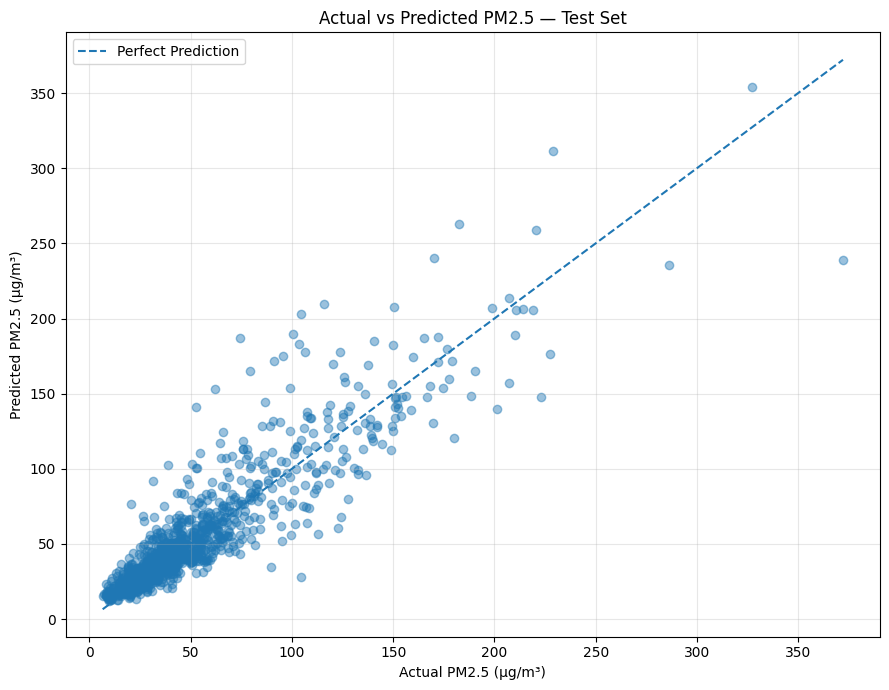

In [6]:
# Actual and predicted values
actual = regression_results["PM2.5_next_day"]
predicted = regression_results["SVR_prediction"]

# Determine common axis limits
min_value = min(actual.min(), predicted.min())
max_value = max(actual.max(), predicted.max())

# Create scatter plot
plt.figure(figsize=(9, 7))

plt.scatter(
    actual,
    predicted,
    alpha=0.45
)

# Perfect prediction reference line
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Predicted PM2.5 (µg/m³)")
plt.title("Actual vs Predicted PM2.5 — Test Set")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save figure
plt.savefig(
    os.path.join(figure_path, "actual_vs_predicted_scatter.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

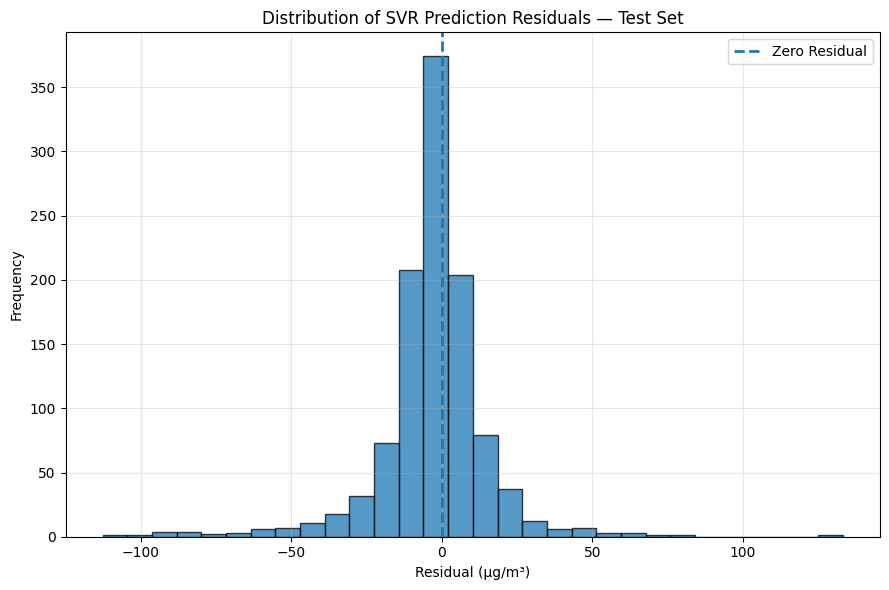

Mean residual: -2.9324
Median residual: -1.8656


In [7]:
# Calculate residuals
residuals = (
    regression_results["PM2.5_next_day"]
    - regression_results["SVR_prediction"]
)

# Create residual distribution plot
plt.figure(figsize=(9, 6))

plt.hist(
    residuals,
    bins=30,
    edgecolor="black",
    alpha=0.75
)

# Zero-error reference line
plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

plt.xlabel("Residual (µg/m³)")
plt.ylabel("Frequency")
plt.title("Distribution of SVR Prediction Residuals — Test Set")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save figure
plt.savefig(
    os.path.join(figure_path, "residual_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean residual:", round(residuals.mean(), 4))
print("Median residual:", round(residuals.median(), 4))

In [8]:
visualization_files = [
    "actual_vs_predicted_timeseries.png",
    "actual_vs_predicted_scatter.png",
    "residual_distribution.png"
]

print("Final Visualization Verification\n")

for filename in visualization_files:
    file_path = os.path.join(figure_path, filename)

    if os.path.exists(file_path):
        size_kb = os.path.getsize(file_path) / 1024
        print(f"✓ {filename} — {size_kb:.2f} KB")
    else:
        print(f"✗ {filename} — NOT FOUND")

Final Visualization Verification

✓ actual_vs_predicted_timeseries.png — 1392.80 KB
✓ actual_vs_predicted_scatter.png — 421.44 KB
✓ residual_distribution.png — 100.03 KB
